# 01 · Satellite data extraction

This notebook downloads the satellite layers used by the UHI model from the [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/) STAC API. It resamples every layer onto the 10 m Sentinel-2 grid and writes the result to GeoTIFFs in `data/processed/`. The loading and compositing logic lives in `uhi.satellite`.

| Section | Collection | Native resolution | Output file(s) |
|---|---|---|---|
| 1 | Sentinel-2 L2A (`sentinel-2-l2a`) | 10 / 20 / 60 m | `Sentinel2_SingleDay_<method>.tiff` (2021-07-24), `Sentinel2_Median_<method>.tiff` |
| 2 | Landsat 8 Collection 2 Level-2 (`landsat-c2-l2`) | 30 m (thermal band 100 m) | `LST_Singleday_<method>_4.tiff` (2021-06-23), `LST_Median_<method>_4.tiff` |
| 3 | MODIS land surface temperature & emissivity, 8-day (`modis-11A2-061`) | 1 km | `LST_Emis_mean_<method>_8.tiff` (composite starting 2021-07-28) |
| 4 | MODIS vegetation indices, 16-day (`modis-13Q1-061`) | 250 m | `VI_mean_<method>_9.tiff` (composite starting 2021-07-28) |

`<method>` is the resampling method set below (`nearest` by default). The study area is the Bronx / Manhattan bounding box and the search window is 1 June – 1 September 2021.

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from rasterio.enums import Resampling

from uhi import config, raster, satellite

# Resampling method used to put every layer on the 10 m Sentinel-2 grid.
# Use Resampling.bilinear to produce the inputs of 03_uhi_model_bilinear.ipynb.
RESAMPLING = Resampling.nearest
names = config.geotiff_names(RESAMPLING.name)
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

catalog = satellite.open_catalog()
print("Study area (min lon, min lat, max lon, max lat):", config.BOUNDS)
print("Search window:", config.TIME_WINDOW)

Study area (min lon, min lat, max lon, max lat): (-74.01, 40.75, -73.86, 40.88)
Search window: 2021-06-01/2021-09-01


## 1. Sentinel-2 L2A

| Band | Description | Resolution |
|---|---|---|
| B01 | Coastal aerosol (443 nm) | 60 m |
| B02 / B03 / B04 | Blue (490 nm) / Green (560 nm) / Red (665 nm) | 10 m |
| B05 / B06 / B07 | Red edge (704 / 740 / 783 nm) | 20 m |
| B08 | NIR (842 nm) | 10 m |
| B8A | Narrow NIR (865 nm) | 20 m |
| B09 | Water vapour (945 nm) | 60 m |
| B11 / B12 | SWIR (1.61 / 2.19 µm) | 20 m |
| AOT, WVP, visual | Aerosol optical thickness, water vapour, true-colour image | 10 m |
| SCL | Scene classification | 20 m |

In [2]:
s2_items = satellite.search(catalog, "sentinel-2-l2a", config.BOUNDS, config.TIME_WINDOW,
                            query={"eo:cloud_cover": {"lt": 30}})
print(f"{len(s2_items)} Sentinel-2 scenes with less than 30% cloud cover")

s2 = satellite.load_sentinel2(s2_items, config.BOUNDS)
s2["10m"]

10 Sentinel-2 scenes with less than 30% cloud cover


<xarray.Dataset> Size: 339MB
Dimensions:      (latitude: 1448, longitude: 1671, time: 10)
Coordinates:
  * latitude     (latitude) float64 12kB 40.88 40.88 40.88 ... 40.75 40.75 40.75
  * longitude    (longitude) float64 13kB -74.01 -74.01 -74.01 ... -73.86 -73.86
    spatial_ref  int32 4B 4326
  * time         (time) datetime64[ns] 80B 2021-06-06T15:38:09.024000 ... 202...
Data variables:
    B02          (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B03          (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B04          (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    B08          (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    AOT          (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    WVP          (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>
    visual       (time, latitude, longitude) uint16 48MB dask.array<chunksize=(1, 1448, 1671), meta=np.ndarray>

### Single-day and median composites
The ground data were collected on **24 July 2021**, so the Sentinel-2 scene of that day is used as a single-day snapshot. A per-pixel median over all scenes gives a seasonal composite that is less affected by clouds. The 20 m and 60 m bands are resampled onto the 10 m grid; this single-day 10 m grid is the target grid of every other layer.

In [3]:
s2_single, s2_median, grid = satellite.sentinel2_composites(s2, config.SURVEY_DATE, RESAMPLING)
raster.write_geotiff(config.PROCESSED_DIR / names["s2_single"], s2_single, config.BOUNDS)
raster.write_geotiff(config.PROCESSED_DIR / names["s2_median"], s2_median, config.BOUNDS)
print("10 m grid:", dict(grid.sizes))

[########################################] | 100% Completed | 37.44 s
[########################################] | 100% Completed | 12.68 s
[########################################] | 100% Completed | 7.44 s
10 m grid: {'latitude': 1448, 'longitude': 1671, 'time': 1}


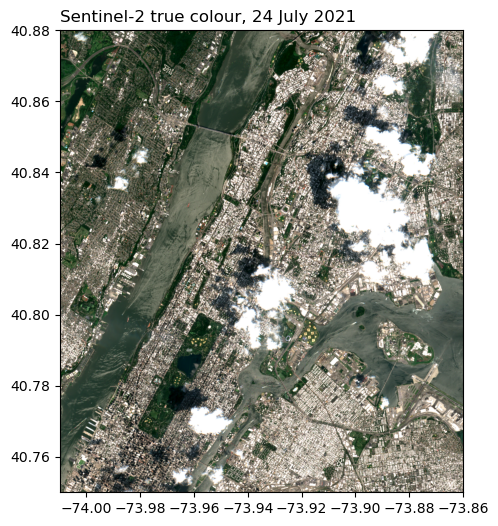

In [4]:
# True-colour preview of the single-day scene (the clouds are the white patches)
rgb = np.dstack([s2_single[b] for b in ("B04", "B03", "B02")])
rgb = np.clip((rgb - 220) / (2700 - 220), 0, 1) ** 0.8

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(rgb, extent=(config.BOUNDS[0], config.BOUNDS[2], config.BOUNDS[1], config.BOUNDS[3]),
          aspect=1 / np.cos(np.radians(40.815)))
ax.set_title("Sentinel-2 true colour, 24 July 2021", loc="left")
plt.show()

## 2. Landsat 8 Collection 2 Level-2

| Band | Description | Resolution |
|---|---|---|
| red, green, blue, coastal | Surface reflectance | 30 m |
| nir08, swir16, swir22 | NIR and SWIR (1.6 / 2.2 µm) reflectance | 30 m |
| lwir11 | Surface temperature | 100 m |
| emis, emsd | Emissivity and its standard deviation | 30 m |
| trad, urad | Thermal radiance, upwelled radiance | 30 m |
| atran | Atmospheric transmittance | 30 m |
| cdist | Distance to the nearest cloud | 30 m |
| qa_pixel, qa_radsat, qa_aerosol | Quality bands | 30 m |

In [5]:
ls_items = satellite.search(catalog, "landsat-c2-l2", config.BOUNDS, config.TIME_WINDOW,
                            query={"eo:cloud_cover": {"lt": 50}, "platform": {"in": ["landsat-8"]}})
print(f"{len(ls_items)} Landsat 8 scenes with less than 50% cloud cover")

landsat = satellite.load_landsat(ls_items, config.BOUNDS)
scaled_30m, scaled_100m = satellite.scale_landsat(landsat)
[str(t)[:10] for t in landsat["30m"].time.values]

8 Landsat 8 scenes with less than 50% cloud cover


['2021-06-07',
 '2021-06-07',
 '2021-06-16',
 '2021-06-23',
 '2021-06-23',
 '2021-07-18',
 '2021-08-26',
 '2021-08-26']

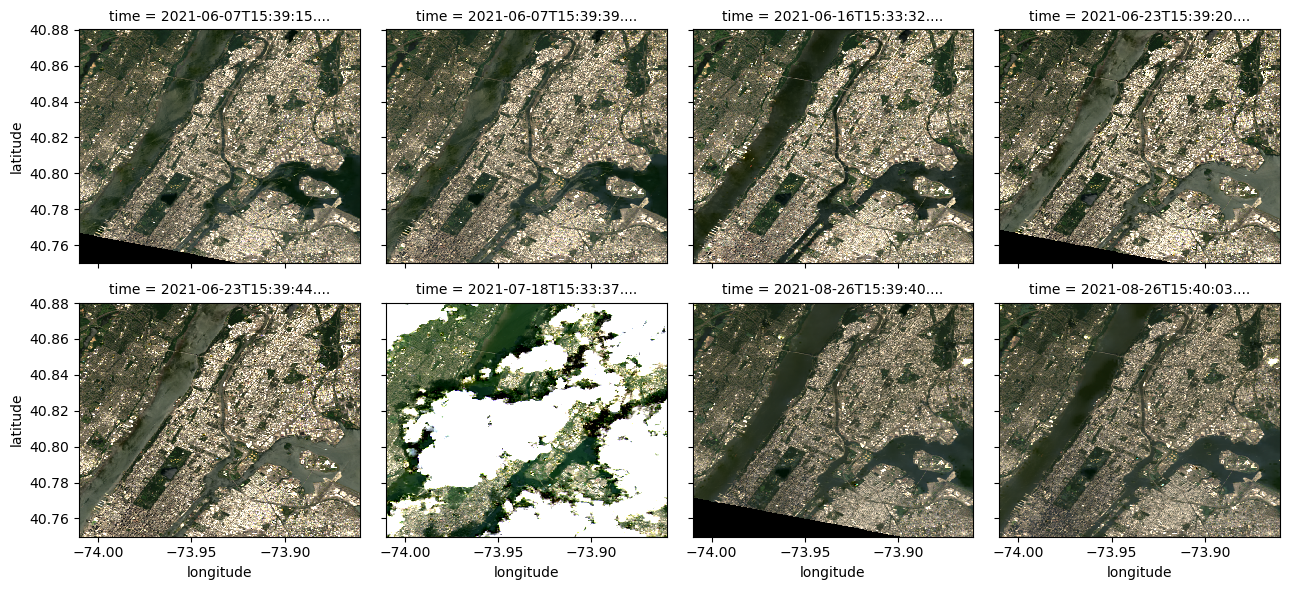

In [6]:
# True-colour preview of every Landsat scene (scaled reflectance clipped to 0-1)
rgb = xr.concat([scaled_30m[b].clip(min=0, max=1) for b in ("red", "green", "blue")], dim="band")
rgb.coords["band"] = ["red", "green", "blue"]
rgb.plot.imshow(col="time", col_wrap=4, robust=True, vmin=0, vmax=0.25)
plt.show()

### Single-scene and median composites
None of the Landsat 8 scenes in the search results was acquired on the survey day. The scene at time index 4 (**2021-06-23**) therefore serves as the single-scene snapshot, next to a per-pixel median over all scenes. Pixels with a raw value of 0 (no data) are masked before the median is computed.

In [7]:
ls_single = satellite.landsat_single_scene(scaled_30m, scaled_100m, config.LANDSAT_TIME_INDEX, grid, RESAMPLING)
ls_median = satellite.landsat_median(scaled_30m, scaled_100m, grid, RESAMPLING)
raster.write_geotiff(config.PROCESSED_DIR / names["landsat_single"], ls_single, config.BOUNDS)
raster.write_geotiff(config.PROCESSED_DIR / names["landsat_median"], ls_median, config.BOUNDS)
list(ls_single)

[########################################] | 100% Completed | 1.61 s
[########################################] | 100% Completed | 1.61 s
[########################################] | 100% Completed | 3.12 s
[########################################] | 100% Completed | 1.51 s
[########################################] | 100% Completed | 1.41 s
[########################################] | 100% Completed | 1.51 s
[########################################] | 100% Completed | 1.31 s
[########################################] | 100% Completed | 1.41 s
[########################################] | 100% Completed | 1.31 s
[########################################] | 100% Completed | 1.31 s
[########################################] | 100% Completed | 1.01 s
[########################################] | 100% Completed | 905.29 ms
[########################################] | 100% Completed | 1.11 s
[########################################] | 100% Completed | 1.09 s
[##############################

['red',
 'green',
 'blue',
 'nir08',
 'swir16',
 'swir22',
 'coastal',
 'emis',
 'emsd',
 'trad',
 'urad',
 'atran',
 'cdist',
 'lwir11']

## 3. MODIS land surface temperature & emissivity (8-day, 1 km)

26 MODIS LST items, 13 8-day composites


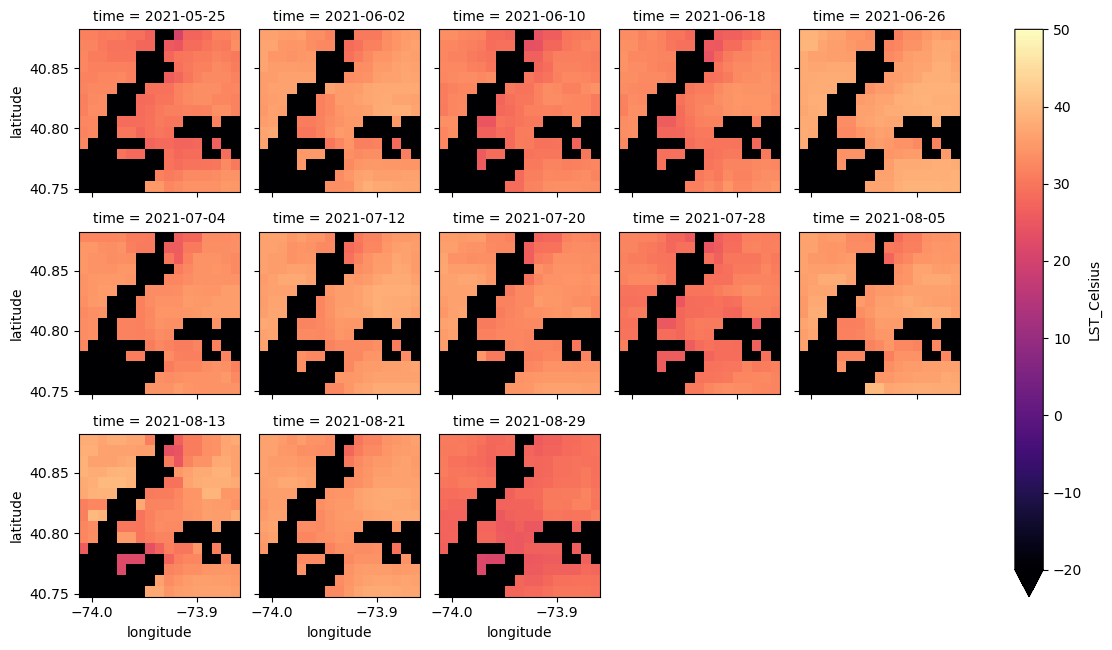

In [8]:
lst_items = satellite.search(catalog, "modis-11A2-061", config.BOUNDS, config.TIME_WINDOW)
modis_lst = satellite.load_modis_lst(lst_items, config.BOUNDS)
print(f"{len(lst_items)} MODIS LST items, {modis_lst.sizes['time']} 8-day composites")

modis_lst["LST_Celsius"].plot.imshow(col="time", col_wrap=5, size=2.2, cmap="magma", vmin=-20, vmax=50)
plt.show()

In [9]:
# Composite at time index 8: the 8-day period starting 2021-07-28
lst = satellite.composite_on_grid(modis_lst, config.MODIS_LST_TIME_INDEX, grid, RESAMPLING)
raster.write_geotiff(config.PROCESSED_DIR / names["modis_lst"], lst, config.BOUNDS)
list(lst)

[########################################] | 100% Completed | 219.73 ms
[########################################] | 100% Completed | 1.24 s
[########################################] | 100% Completed | 1.31 s


['LST_Celsius', 'Emis_31', 'Emis_32']

## 4. MODIS vegetation indices (16-day, 250 m)

14 MODIS vegetation-index items, 14 16-day composites


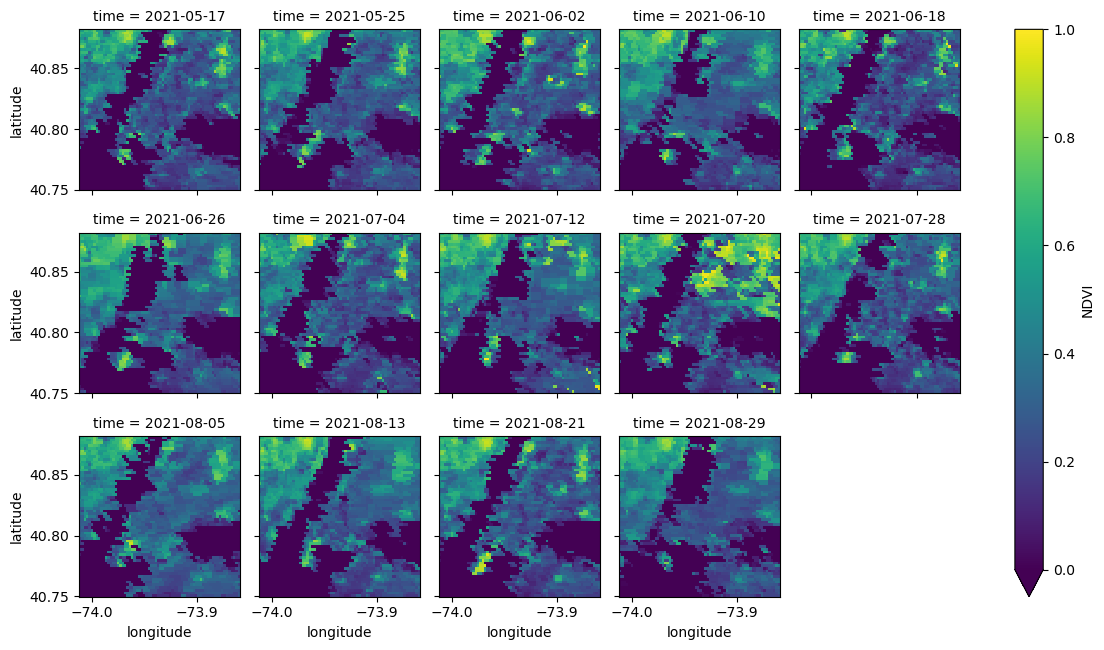

In [10]:
vi_items = satellite.search(catalog, "modis-13Q1-061", config.BOUNDS, config.TIME_WINDOW)
modis_vi = satellite.load_modis_vi(vi_items, config.BOUNDS)
print(f"{len(vi_items)} MODIS vegetation-index items, {modis_vi.sizes['time']} 16-day composites")

modis_vi["NDVI"].plot.imshow(col="time", col_wrap=5, size=2.2, cmap="viridis", vmin=0, vmax=1)
plt.show()

In [11]:
# Composite at time index 9: the 16-day period starting 2021-07-28
vi = satellite.composite_on_grid(modis_vi, config.MODIS_VI_TIME_INDEX, grid, RESAMPLING)
raster.write_geotiff(config.PROCESSED_DIR / names["modis_vi"], vi, config.BOUNDS)
list(vi)

[########################################] | 100% Completed | 100.87 ms
[########################################] | 100% Completed | 2.42 s


['NDVI', 'EVI']

## Output files

In [12]:
for name in names.values():
    path = config.PROCESSED_DIR / name
    print(f"{name:36s} {path.stat().st_size / 1e6:7.1f} MB")

Sentinel2_SingleDay_nearest.tiff        84.3 MB
Sentinel2_Median_nearest.tiff           90.2 MB
LST_Singleday_nearest_4.tiff           157.1 MB
LST_Median_nearest_4.tiff              161.3 MB
LST_Emis_mean_nearest_8.tiff             7.0 MB
VI_mean_nearest_9.tiff                   9.0 MB
